In [2]:
# ============================================================
# CEK DATASET
# ============================================================

import os


print(os.listdir(r'D:\nensi\CCR-HandWriting\data\Trainmdb'))
print(os.listdir(r'D:\nensi\CCR-HandWriting\data\Testmdb'))


['data.mdb', 'lock.mdb']
['data.mdb', 'lock.mdb']


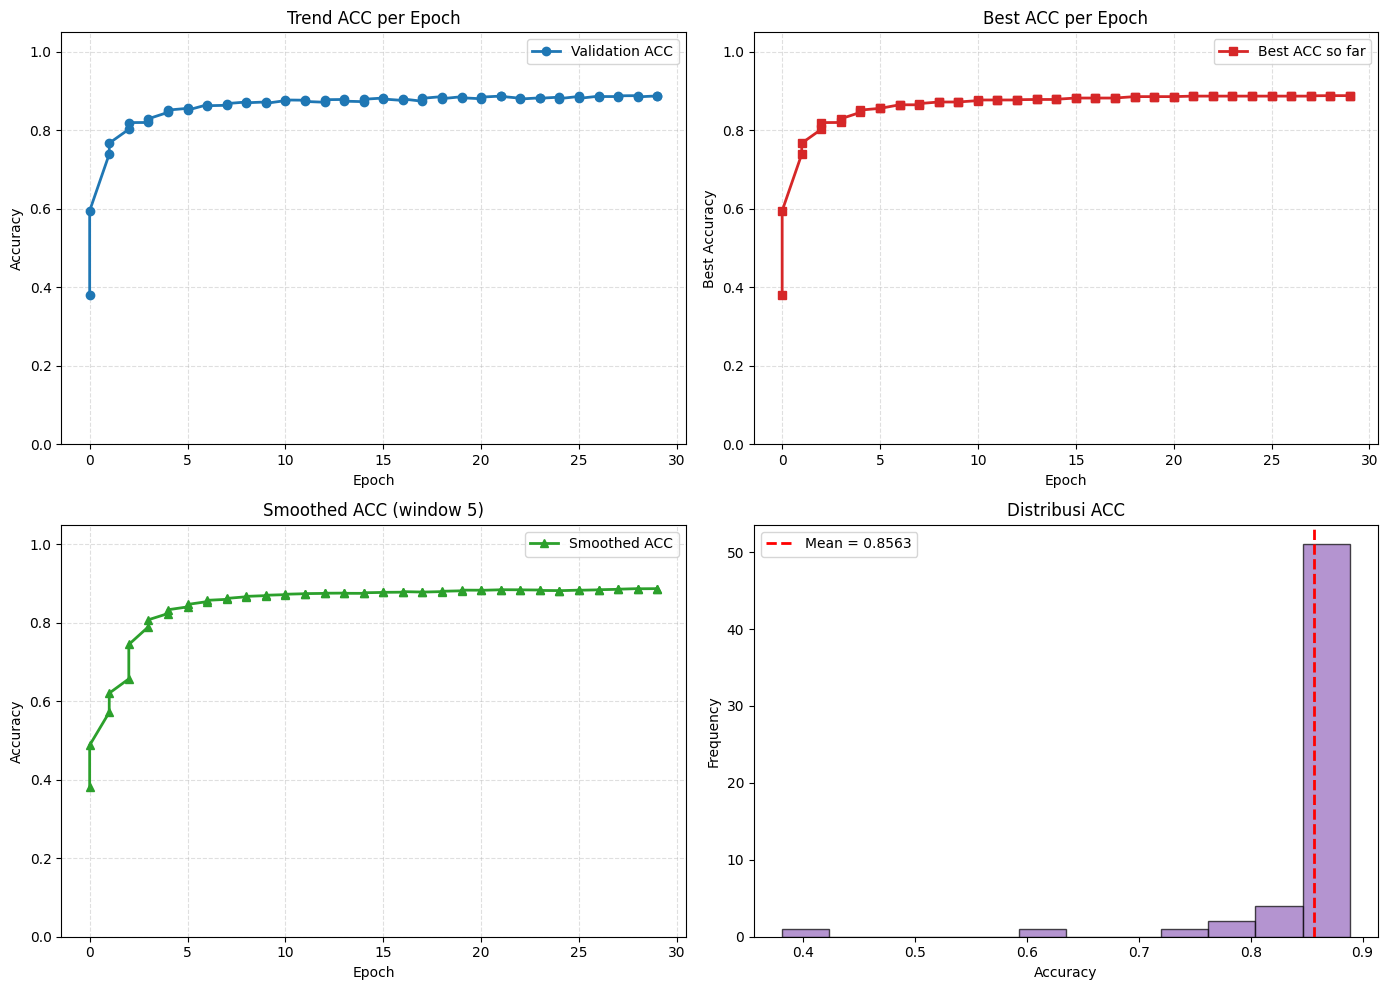

Best ACC: 0.888616
Last ACC: 0.886610
Mean ACC: 0.856265


In [4]:
# ============================================================
# PLOT HASIL TRAINING (MULTI-GRAFIK)
# ============================================================

import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

record_path = Path(r'D:\nensi\CCR-HandWriting\history\【0001】FULLDATASET TRAIN\record.txt')

if not record_path.exists():
    raise FileNotFoundError(f'File log tidak ditemukan: {record_path}')

pattern = re.compile(r"Epoch\s*:\s*(\d+)\s*\|\s*ACC\s*:\s*([0-9eE.+-]+)")

epochs = []
accs = []
best_accs = []
smoothed_accs = []
best_so_far = 0.0

with open(record_path, 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        m = pattern.search(line)
        if m:
            epoch = int(m.group(1))
            acc = float(m.group(2))
            epochs.append(epoch)
            accs.append(acc)
            if acc > best_so_far:
                best_so_far = acc
            best_accs.append(best_so_far)

for i in range(len(accs)):
    window = min(5, i + 1)
    smoothed_accs.append(np.mean(accs[i - window + 1:i + 1]))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Trend ACC per epoch
axes[0, 0].plot(epochs, accs, marker='o', linewidth=2, color='tab:blue', label='Validation ACC')
axes[0, 0].set_title('Trend ACC per Epoch')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].grid(True, linestyle='--', alpha=0.4)
axes[0, 0].legend()
axes[0, 0].set_ylim(0, 1.05)

# 2. Best ACC so far
axes[0, 1].plot(epochs, best_accs, marker='s', linewidth=2, color='tab:red', label='Best ACC so far')
axes[0, 1].set_title('Best ACC per Epoch')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Best Accuracy')
axes[0, 1].grid(True, linestyle='--', alpha=0.4)
axes[0, 1].legend()
axes[0, 1].set_ylim(0, 1.05)

# 3. Smoothed ACC
axes[1, 0].plot(epochs, smoothed_accs, marker='^', linewidth=2, color='tab:green', label='Smoothed ACC')
axes[1, 0].set_title('Smoothed ACC (window 5)')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].grid(True, linestyle='--', alpha=0.4)
axes[1, 0].legend()
axes[1, 0].set_ylim(0, 1.05)

# 4. Histogram distribution ACC
axes[1, 1].hist(accs, bins=12, color='tab:purple', edgecolor='black', alpha=0.7)
axes[1, 1].axvline(np.mean(accs), color='red', linestyle='--', linewidth=2, label=f'Mean = {np.mean(accs):.4f}')
axes[1, 1].set_title('Distribusi ACC')
axes[1, 1].set_xlabel('Accuracy')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

print(f'Best ACC: {max(best_accs):.6f}')
print(f'Last ACC: {accs[-1]:.6f}')
print(f'Mean ACC: {np.mean(accs):.6f}')


=== RINGKASAN HISTORY 0001 ===
Jumlah record: 60
Best epoch: 28
Best ACC: 0.888616
Last ACC: 0.886610
Mean ACC: 0.856265
Folder history: D:\nensi\CCR-HandWriting\history\【0001】FULLDATASET TRAIN


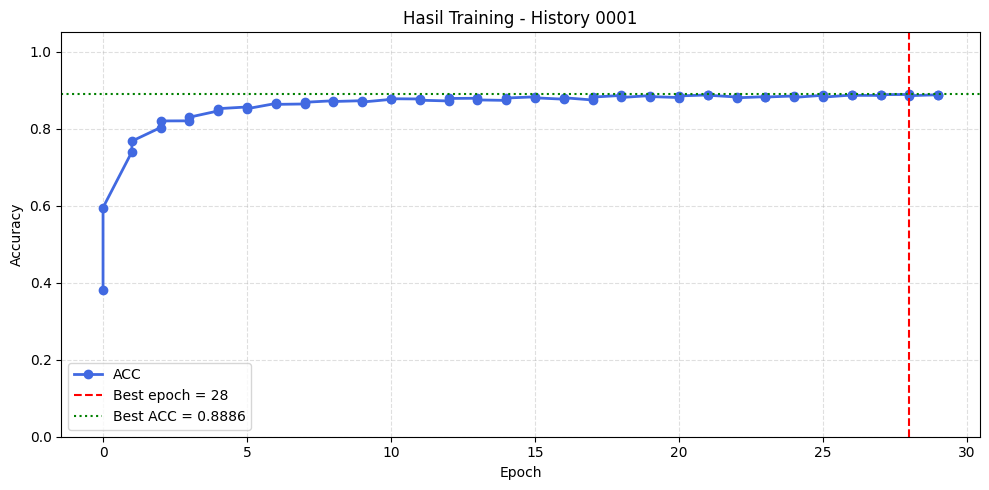


File yang tersedia di folder history:
- 2026-10-03_12-14-16
- accuracy_record.txt
- best_model.pth
- config.py
- events.out.tfevents.1791000856.DESKTOP-JNBSL01.5848.0
- last_epoch.txt
- last_iter.txt
- model.pth
- record.txt
- record_plot.png
- train.py
- transformer.py
- util.py


In [5]:
# ============================================================
# RINGKASAN HASIL TRAINING DARI FOLDER HISTORY 0001
# ============================================================

import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

history_root = Path(r'D:\nensi\CCR-HandWriting\history\【0001】FULLDATASET TRAIN')
record_path = history_root / 'record.txt'

if not record_path.exists():
    raise FileNotFoundError(f'File record tidak ditemukan: {record_path}')

# Baca file record
pattern = re.compile(r"Epoch\s*:\s*(\d+)\s*\|\s*ACC\s*:\s*([0-9eE.+-]+)")

epochs = []
accs = []

with open(record_path, 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        m = pattern.search(line)
        if m:
            epochs.append(int(m.group(1)))
            accs.append(float(m.group(2)))

if not accs:
    raise ValueError(f'Tidak ada data ACC di {record_path}')

best_epoch = epochs[np.argmax(accs)]
best_acc = max(accs)
last_acc = accs[-1]
mean_acc = np.mean(accs)

print('=== RINGKASAN HISTORY 0001 ===')
print(f'Jumlah record: {len(accs)}')
print(f'Best epoch: {best_epoch}')
print(f'Best ACC: {best_acc:.6f}')
print(f'Last ACC: {last_acc:.6f}')
print(f'Mean ACC: {mean_acc:.6f}')
print(f'Folder history: {history_root}')

# Plot sederhana untuk visual cepat
plt.figure(figsize=(10, 5))
plt.plot(epochs, accs, marker='o', color='royalblue', linewidth=2, label='ACC')
plt.axvline(best_epoch, color='red', linestyle='--', linewidth=1.5, label=f'Best epoch = {best_epoch}')
plt.axhline(best_acc, color='green', linestyle=':', linewidth=1.5, label=f'Best ACC = {best_acc:.4f}')
plt.title('Hasil Training - History 0001')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

# Cek file yang ada di folder history
print('\nFile yang tersedia di folder history:')
for item in sorted(history_root.iterdir()):
    print('-', item.name)


Model dilatih selama 30 epoch dan mencapai best accuracy sebesar 0.8886 pada epoch ke-28. Akurasi terakhir tercatat 0.8866 dengan rata-rata akurasi sekitar 0.8563. Hal ini menunjukkan model sudah mampu belajar dengan baik dan mencapai performa yang stabil di kisaran 0.88–0.89. Meskipun hasil ini sudah cukup baik, masih ada ruang peningkatan untuk mencapai target di atas 0.90 melalui tuning parameter dan eksperimen lebih lanjut.

C:\Users\User\AppData\Local\Temp\ipykernel_21536\1391498917.py:56: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(checkpoint_path, map_location=DEVICE

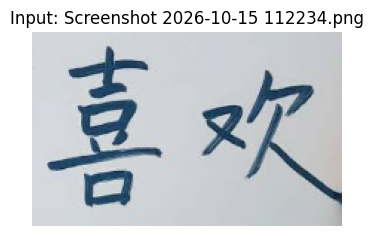

=== HASIL TESTING ===
File               : C:\Users\User\Pictures\Screenshots\Screenshot 2026-10-15 112234.png
Hanzi digital      : 彭
Kandidat Hanzi     : 彭
Pinyin             : peng
Arti bahasa Inggris: Arti bahasa Inggris belum tersedia di data kamus lokal
Prediksi stroke    : 121251431333
Confidence model   : 98.80%


In [14]:
# ============================================================
# TESTING MANUAL: PILIH GAMBAR -> HANZI, PINYIN, DAN ARTI
# ============================================================

import json
import tkinter as tk
from tkinter import filedialog
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms

from config import config
from model.transformer import Transformer
from util import character_to_strokelist, get_alphabet, rectify

try:
    from pypinyin import lazy_pinyin
except ImportError:
    lazy_pinyin = None


CHECKPOINT_PATH = Path(r'D:\nensi\CCR-HandWriting\history\【0001】FULLDATASET TRAIN\best_model.pth')
MEANINGS_PATH = Path(r'D:\nensi\CCR-HandWriting\data\hanzi_meanings.json')
IMAGE_SIZE = config['image_size']
MODE = config['mode']
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ALPHABET = get_alphabet(MODE)

if MEANINGS_PATH.exists():
    with open(MEANINGS_PATH, 'r', encoding='utf-8') as file:
        HANZI_MEANINGS = json.load(file)
else:
    HANZI_MEANINGS = {}


def get_hanzi_info(hanzi):
    if lazy_pinyin is None:
        pinyin = 'Tidak tersedia: install pypinyin terlebih dahulu'
    else:
        pinyin = ' '.join(lazy_pinyin(hanzi))
    meaning = HANZI_MEANINGS.get(
        hanzi,
        'Arti bahasa Inggris belum tersedia di data kamus lokal'
    )
    return pinyin, meaning


def load_model(checkpoint_path):
    if not checkpoint_path.exists():
        raise FileNotFoundError(f'Checkpoint tidak ditemukan: {checkpoint_path}')
    model = Transformer(MODE).to(DEVICE)
    state_dict = torch.load(checkpoint_path, map_location=DEVICE)
    cleaned_state_dict = {}
    for key, value in state_dict.items():
        if key.startswith('module.'):
            key = key[7:]
        cleaned_state_dict[key] = value
    model.load_state_dict(cleaned_state_dict)
    model.eval()
    return model


def choose_image():
    root = tk.Tk()
    root.withdraw()
    root.attributes('-topmost', True)
    selected = filedialog.askopenfilename(
        title='Pilih gambar tulisan tangan',
        filetypes=[
            ('File gambar', '*.png *.jpg *.jpeg *.bmp *.webp'),
            ('Semua file', '*.*'),
        ],
    )
    root.destroy()
    return Path(selected) if selected else None


def predict_image(model, image_path, max_length=30):
    original_image = Image.open(image_path).convert('RGB')
    preprocess = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ])
    image = preprocess(original_image).unsqueeze(0).to(DEVICE)
    predicted_tokens = torch.zeros((1, 1), dtype=torch.long, device=DEVICE)
    token_confidences = []
    image_features = None
    end_token = len(ALPHABET) - 1

    with torch.no_grad():
        for step in range(max_length):
            text_length = torch.tensor([step + 1], dtype=torch.long, device=DEVICE)
            result = model(
                image,
                text_length,
                predicted_tokens,
                conv_feature=image_features,
                test=True,
            )
            probabilities = F.softmax(result['pred'], dim=2)
            next_token = probabilities[:, -1, :].argmax(dim=1)
            token_confidences.append(float(probabilities[0, -1, next_token].item()))
            predicted_tokens = torch.cat(
                [predicted_tokens, next_token.view(1, 1)], dim=1
            )
            image_features = result['conv']
            if int(next_token.item()) == end_token:
                break

    token_ids = predicted_tokens[0, 1:].tolist()
    raw_stroke = ''.join(
        ALPHABET[token_id] for token_id in token_ids if token_id != end_token
    )
    rectified_stroke = rectify(MODE, raw_stroke)
    candidates = [
        character
        for character, stroke in character_to_strokelist.items()
        if stroke == rectified_stroke
    ]
    return {
        'image': original_image,
        'raw_stroke': raw_stroke,
        'stroke': rectified_stroke,
        'candidates': candidates,
        'confidence': sum(token_confidences) / len(token_confidences),
    }


model = load_model(CHECKPOINT_PATH)
image_path = choose_image()

if image_path is None:
    print('Tidak ada gambar yang dipilih.')
else:
    result = predict_image(model, image_path)
    candidates = result['candidates']
    predicted_hanzi = candidates[0] if candidates else '(tidak ditemukan)'
    predicted_pinyin, predicted_meaning = get_hanzi_info(predicted_hanzi)

    plt.figure(figsize=(4, 4))
    plt.imshow(result['image'])
    plt.axis('off')
    plt.title(f'Input: {image_path.name}')
    plt.show()

    print('=== HASIL TESTING ===')
    print(f'File               : {image_path}')
    print(f'Hanzi digital      : {predicted_hanzi}')
    print(f'Kandidat Hanzi     : {"".join(candidates) if candidates else "-"}')
    print(f'Pinyin             : {predicted_pinyin}')
    print(f'Arti bahasa Inggris: {predicted_meaning}')
    print(f'Prediksi stroke    : {result["stroke"]}')
    print(f'Confidence model   : {result["confidence"]:.2%}')
